# Lab 6 - Sentiment Analysis: Tweets

Do a sentiment analysis on the [syedkhalid076/Sentiment-Analysis](https://huggingface.co/datasets/syedkhalid076/Sentiment-Analysis) dataset. This dataset contains tweets (use only 10k samples for train dataset).

This dataset is designed for sentiment analysis tasks, providing labeled examples across three sentiment categories:
- 0: Negative
- 1: Neutral
- 2: Positive

## Import Libraries

In [1]:
# import required libraries
import re
import unicodedata

import matplotlib.pyplot as plt
import nltk
import pandas as pd
import seaborn as sns
import spacy
from afinn import Afinn
from bs4 import BeautifulSoup
from contractions import contractions_dict
from datasets import load_dataset
from ftfy import fix_text
from nltk.corpus import sentiwordnet as swn
from nltk.tokenize.toktok import ToktokTokenizer
from sklearn.base import clone
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB


In [2]:
# Load nltk resources
nltk.download('sentiwordnet')
nltk.download('stopwords')
nltk.download('wordnet')


[nltk_data] Downloading package sentiwordnet to
[nltk_data]     /Users/Rory/nltk_data...
[nltk_data]   Package sentiwordnet is already up-to-date!
[nltk_data] Downloading package stopwords to /Users/Rory/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/Rory/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

## Load Data

Loading code from the brief, with its `your-dataset-path` placeholder replaced by the dataset's Hugging Face id.

In [3]:
# Load the dataset
dataset = load_dataset('syedkhalid076/Sentiment-Analysis')

# Access splits
train_data = dataset['train']
validation_data = dataset['validation']
test_data = dataset['test']

# Example: Printing a sample
print(train_data[0])

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


{'text': 'almost got in a giant car accident on the 101', 'label': 0}


Convert the splits to DataFrames, using a random sample of 10k rows, stratified. Validation and test are kept in full.

In [4]:
# convert splits to dataframes, keeping a stratified 10k training sample
full_train_df = train_data.to_pandas()
train_df, _ = train_test_split(
    full_train_df,
    train_size=10_000,
    stratify=full_train_df['label'],
    random_state=37,
)
train_df = train_df.reset_index(drop=True)
validation_df = validation_data.to_pandas()
test_df = test_data.to_pandas()

label_names = ['Negative', 'Neutral', 'Positive']

train_df.head()

,text,label
0,in the tiny events that could make a person wh...,2
1,remain curious about each other against all odds,2
2,"the overcooked , ham-fisted direction",0
3,i was so bored i decided to iron all my baju s...,1
4,nair 's attention to detail,2


## Exploratory Data Analysis

In [5]:
# run standard checks
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    10000 non-null  str  
 1   label   10000 non-null  int64
dtypes: int64(1), str(1)
memory usage: 926.0 KB


In [6]:
train_df.shape, validation_df.shape, test_df.shape

((10000, 2), (10499, 2), (10499, 2))

In [7]:
train_df.duplicated().sum()

np.int64(0)

In [8]:
train_df.isna().sum()

text     0
label    0
dtype: int64

In [9]:
train_df['label'].value_counts(normalize=True)

label
2    0.4817
0    0.3988
1    0.1195
Name: proportion, dtype: float64

### Text length

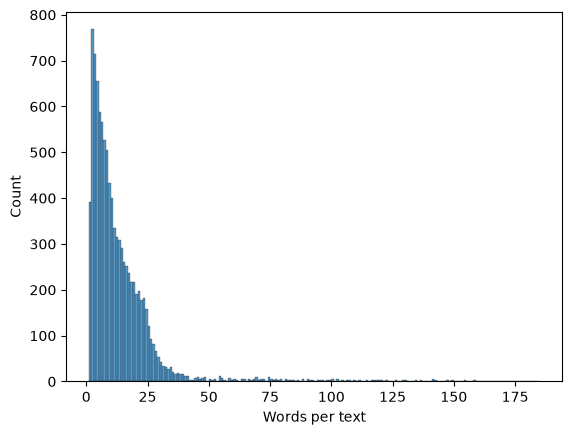

In [10]:
# number of words in each text
word_counts = train_df['text'].str.split().str.len()

# distribution of text length
sns.histplot(word_counts, binwidth=1)
plt.xlabel('Words per text')
plt.show()

## Text Pre-Processing and Normalisation

Cleaning and normalising the text before modelling.

In [11]:
# normaliser set-up, from the lecture's text_normaliser.py
nlp = spacy.load('en_core_web_sm')
tokenizer = ToktokTokenizer()
stopword_list = nltk.corpus.stopwords.words('english')
stopword_list.remove('no')
stopword_list.remove('not')

### Function Set Up
Adapted from module notebook

In [12]:
def strip_html_tags(text):
    soup = BeautifulSoup(text, 'html.parser')
    stripped_text = soup.get_text()
    return stripped_text


def remove_accented_chars(text):
    text = (
        unicodedata.normalize('NFKD', text)
        .encode('ascii', 'ignore')
        .decode('utf-8', 'ignore')
    )
    return text


def expand_contractions(text, contraction_mapping=contractions_dict):
    contractions_pattern = re.compile(
        '({})'.format('|'.join(contraction_mapping.keys())),
        flags=re.IGNORECASE | re.DOTALL,
    )

    def expand_match(contraction):
        match = contraction.group(0)
        first_char = match[0]
        if contraction_mapping.get(match) is not None:
            expanded_contraction = (
                contraction_mapping.get(match)
                if contraction_mapping.get(match)
                else contraction_mapping.get(match.lower())
            )
            expanded_contraction = first_char + expanded_contraction[1:]
            return expanded_contraction
        else:
            return match

    expanded_text = contractions_pattern.sub(expand_match, text)
    expanded_text = re.sub("'", '', expanded_text)
    return expanded_text


def remove_special_characters(text):
    text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
    return text


def lemmatize_text(text):
    text = nlp(text)
    text = ' '.join(
        [word.lemma_ if word.lemma_ != '-PRON-' else word.text for word in text]
    )
    return text


def remove_stopwords(text, is_lower_case=False):
    tokens = tokenizer.tokenize(text)
    tokens = [token.strip() for token in tokens]
    if is_lower_case:
        filtered_tokens = [token for token in tokens if token not in stopword_list]
    else:
        filtered_tokens = [
            token for token in tokens if token.lower() not in stopword_list
        ]
    filtered_text = ' '.join(filtered_tokens)
    return filtered_text

In [13]:
def normalize_corpus(
    corpus,
    *,
    encoding_repair=True,
    html_stripping=True,
    contraction_expansion=True,
    accented_char_removal=True,
    text_lower_case=True,
    text_lemmatization=True,
    special_char_removal=True,
    stopword_removal=True,
):
    normalized_corpus = []

    for doc in corpus:
        text = doc

        # added: repair encoding errors
        if encoding_repair:
            text = fix_text(text)

        if html_stripping:
            text = strip_html_tags(text)

        if accented_char_removal:
            text = remove_accented_chars(text)

        if contraction_expansion:
            text = expand_contractions(text)

        if text_lower_case:
            text = text.lower()

        # remove extra newlines
        text = re.sub(r'[\r|\n|\r\n]+', ' ', text)
        # insert spaces between special characters to isolate them
        special_char_pattern = re.compile(r'([{.(-)!}])')
        text = special_char_pattern.sub(' \\1 ', text)

        if text_lemmatization:
            text = lemmatize_text(text)

        if special_char_removal:
            text = remove_special_characters(text)

        # remove extra whitespace
        text = re.sub(' +', ' ', text)

        if stopword_removal:
            text = remove_stopwords(text, is_lower_case=text_lower_case)

        normalized_corpus.append(text)

    return normalized_corpus

In [14]:
# normalise all three splits
train_df['clean_text'] = normalize_corpus(train_df['text'])
validation_df['clean_text'] = normalize_corpus(validation_df['text'])
test_df['clean_text'] = normalize_corpus(test_df['text'])

In [15]:
# Examine text change.
train_df[['text', 'clean_text']].sample(10, random_state=37)

,text,clean_text
8145,"going at a rapid pace , occasionally",go rapid pace occasionally
1196,would choose the cliff-notes over reading a fu...,would choose cliff note read full length classic
2617,very funny as you peek at it through the finge...,funny peek finger front eye
2249,"veers into corny sentimentality , probably",veer corny sentimentality probably
3956,melodrama and,melodrama
3882,is not as well-conceived as either of those fi...,not well conceive either film
9304,can only point the way -- but thank goodness f...,point way thank goodness signpost
7287,Good morning... IÃÂÃÂÃÂÃÂ¯ÃÂÃÂÃÂÃ...,good morning I soooo tierd
876,it 'll probably be in video stores by christma...,probably video store christmas
4764,"literary purists may not be pleased , but as f...",literary purist may not pleased far mainstream...


## 1. Use the two approaches covered in class and compare them with the best. (classifier and use the linguistic resource)

### Approach 1: Supervised Classifier

In [16]:
cv = CountVectorizer(ngram_range=(1, 2))
tv = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)

cv_train = cv.fit_transform(train_df['clean_text'])
cv_val = cv.transform(validation_df['clean_text'])
cv_test = cv.transform(test_df['clean_text'])

tv_train = tv.fit_transform(train_df['clean_text'])
tv_val = tv.transform(validation_df['clean_text'])
tv_test = tv.transform(test_df['clean_text'])

cv_train.shape, tv_train.shape

((10000, 67316), (10000, 67316))

In [17]:
# the three classifiers from the lecture, and the two feature sets
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=37),
    'SVM': SGDClassifier(loss='hinge', random_state=37),
    'Naive Bayes': MultinomialNB(),
}
feature_sets = {
    'BOW': (cv_train, cv_val, cv_test),
    'TF-IDF': (tv_train, tv_val, tv_test),
}

### Classifier Ranking

In [18]:
# train each model on each feature set and score it on the validation split
y_train = train_df['label']
y_val = validation_df['label']
y_test = test_df['label']

fitted = {}
val_rows = []
for features, (X_train, X_val, _) in feature_sets.items():
    for name, model in models.items():
        clf = clone(model).fit(X_train, y_train)
        fitted[(name, features)] = clf
        val_pred = clf.predict(X_val)
        val_rows.append(
            {
                'approach': 'Classifier',
                'model': name,
                'features': features,
                'accuracy': accuracy_score(y_val, val_pred),
                'macro F1': f1_score(y_val, val_pred, average='macro'),
            }
        )

classifier_val = (
    pd.DataFrame(val_rows).sort_values('macro F1', ascending=False).reset_index(drop=True)
)
classifier_val.round(3)

,approach,model,features,accuracy,macro F1
0,Classifier,SVM,TF-IDF,0.745,0.659
1,Classifier,SVM,BOW,0.730,0.638
2,Classifier,Logistic Regression,TF-IDF,0.734,0.635
3,Classifier,Logistic Regression,BOW,0.730,0.629
4,Classifier,Naive Bayes,BOW,0.717,0.559
5,Classifier,Naive Bayes,TF-IDF,0.708,0.497


In [19]:
best = classifier_val.iloc[0]
best_clf = fitted[(best['model'], best['features'])]
clf_pred = best_clf.predict(feature_sets[best['features']][2])

print(f'Best: {best["model"]} with {best["features"]}\n')
print(classification_report(y_test, clf_pred, target_names=label_names))

Best: SVM with TF-IDF

              precision    recall  f1-score   support

    Negative       0.75      0.75      0.75      4187
     Neutral       0.58      0.33      0.42      1255
    Positive       0.76      0.85      0.80      5057

    accuracy                           0.75     10499
   macro avg       0.70      0.64      0.66     10499
weighted avg       0.74      0.75      0.74     10499



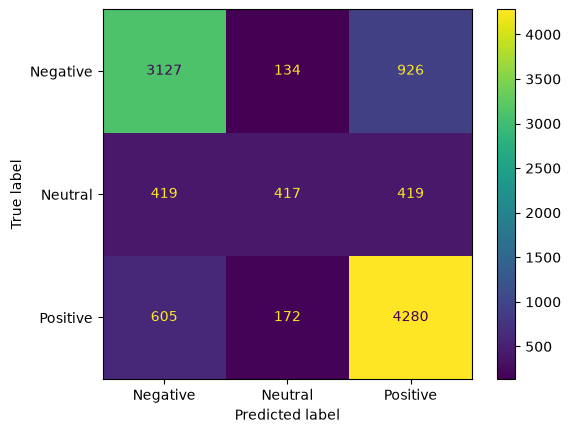

In [20]:
# Visualise scoring.
ConfusionMatrixDisplay.from_predictions(y_test, clf_pred, display_labels=label_names)
plt.show()

SVM with TF-IDF scored highest of the classifiers, however performance on neutral sentiment remaining low with an f1-score of 0.42.

### Approach 2: Lexicon-Based Model (Linguistic Resource)

In [21]:
# AFINN: sum of word and emoticon scores on the raw text
afn = Afinn(emoticons=True)
validation_df['afinn'] = validation_df['text'].apply(afn.score)
test_df['afinn'] = test_df['text'].apply(afn.score)
test_df[['text', 'afinn']].head()

,text,afinn
0,find a spark of its own,1.0
1,oh come on .,0.0
2,winningly,0.0
3,an old-fashioned but emotionally stirring adve...,4.0
4,"salt and vinegar, cheese and onion make your ...",3.0


In [22]:
def polarity_to_label(score):
    """Map a polarity score to 0 (negative), 1 (neutral) or 2 (positive)."""
    if score > 0:
        return 2
    if score < 0:
        return 0
    return 1

Adapted from the module's function for analysing sentiment.

In [23]:
def sentiwordnet_polarity(text):
    """Average positive minus negative SentiWordNet score of a text's words.

    Returns 0 when no word in the text is found in SentiWordNet.
    """
    pos_score = neg_score = token_count = 0
    for token in nlp(text):
        # map the spaCy tag to a WordNet part of speech
        if 'NN' in token.tag_:
            wordnet_pos = 'n'
        elif 'VB' in token.tag_:
            wordnet_pos = 'v'
        elif 'JJ' in token.tag_:
            wordnet_pos = 'a'
        elif 'RB' in token.tag_:
            wordnet_pos = 'r'
        else:
            continue

        ss_set = next(iter(swn.senti_synsets(token.text, wordnet_pos)), None)
        if ss_set:
            pos_score += ss_set.pos_score()
            neg_score += ss_set.neg_score()
            token_count += 1

    if token_count == 0:
        return 0.0
    return round((pos_score - neg_score) / token_count, 2)

In [24]:
validation_df['swn'] = validation_df['clean_text'].apply(sentiwordnet_polarity)
test_df['swn'] = test_df['clean_text'].apply(sentiwordnet_polarity)
test_df[['clean_text', 'swn']].head()

,clean_text,swn
0,find spark,0.00
1,oh come,0.00
2,winningly,0.00
3,old fashioned emotionally stir adventure tale ...,0.07
4,salt vinegar cheese onion make breathe smell lol,0.00


In [25]:
# score both lexicons on the validation split
lexicon_rows = []
for method, column in [('AFINN', 'afinn'), ('SentiWordNet', 'swn')]:
    val_pred = validation_df[column].apply(polarity_to_label)
    lexicon_rows.append(
        {
            'approach': 'Lexicon',
            'model': method,
            'features': '-',
            'accuracy': accuracy_score(y_val, val_pred),
            'macro F1': f1_score(y_val, val_pred, average='macro'),
        }
    )

lexicon_val = pd.DataFrame(lexicon_rows)
lexicon_val.round(3)

,approach,model,features,accuracy,macro F1
0,Lexicon,AFINN,-,0.535,0.496
1,Lexicon,SentiWordNet,-,0.524,0.465


### Comparison

In [26]:
# every method tested on validation
(
    pd.concat([classifier_val, lexicon_val])
    .sort_values('macro F1', ascending=False)
    .reset_index(drop=True)
    .round(3)
)

,approach,model,features,accuracy,macro F1
0,Classifier,SVM,TF-IDF,0.745,0.659
1,Classifier,SVM,BOW,0.730,0.638
2,Classifier,Logistic Regression,TF-IDF,0.734,0.635
3,Classifier,Logistic Regression,BOW,0.730,0.629
4,Classifier,Naive Bayes,BOW,0.717,0.559
5,Classifier,Naive Bayes,TF-IDF,0.708,0.497
6,Lexicon,AFINN,-,0.535,0.496
7,Lexicon,SentiWordNet,-,0.524,0.465


In [27]:
test_preds = {
    f'{best["model"]} ({best["features"]})': clf_pred,
    'AFINN': test_df['afinn'].apply(polarity_to_label),
    'SentiWordNet': test_df['swn'].apply(polarity_to_label),
}

test_rows = []
for method, pred in test_preds.items():
    per_class = f1_score(y_test, pred, average=None)
    test_rows.append(
        {
            'method': method,
            'accuracy': accuracy_score(y_test, pred),
            'macro F1': f1_score(y_test, pred, average='macro'),
            **{f'F1 {name}': f1 for name, f1 in zip(label_names, per_class, strict=True)},
        }
    )

test_results = pd.DataFrame(test_rows).set_index('method')
test_results.round(3)

,accuracy,macro F1,F1 Negative,F1 Neutral,F1 Positive
method,,,,,
SVM (TF-IDF),0.745,0.658,0.750,0.422,0.801
AFINN,0.542,0.501,0.558,0.276,0.670
SentiWordNet,0.523,0.465,0.541,0.242,0.613


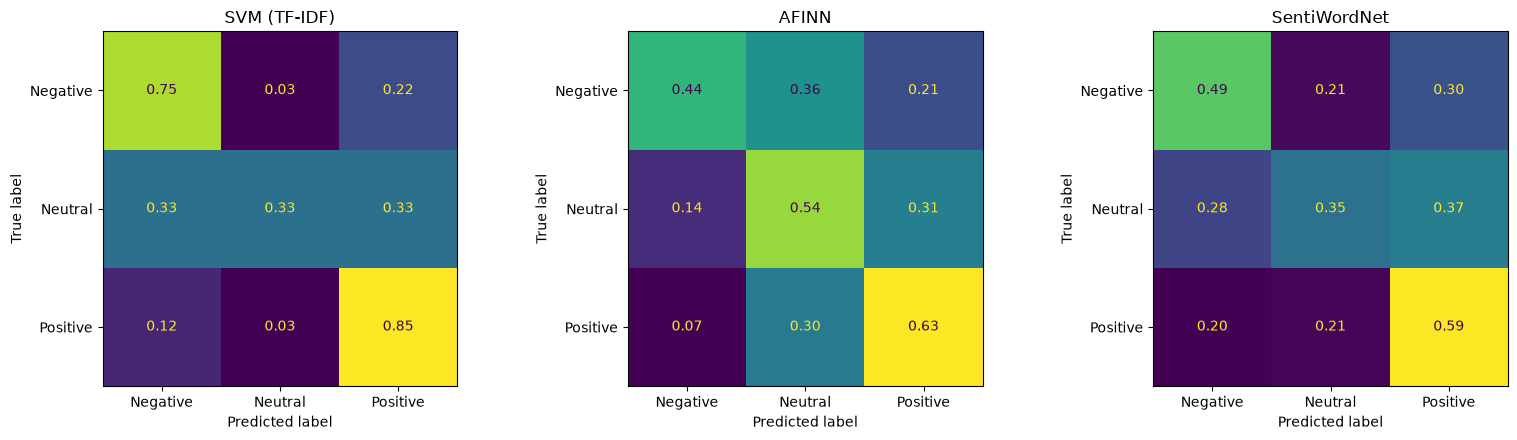

In [ ]:
# confusion matrices of the models
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (method, pred) in zip(axes, test_preds.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred,
        display_labels=label_names,
        normalize='true',
        values_format='.2f',
        colorbar=False,
        ax=ax,
    )
    ax.set_title(method)
plt.tight_layout()
plt.show()

## 2. Notice that the text in the dataset is very short in some cases, so the accuracy of models may be relatively low.

Briefly discuss how you can potentially address this problem (short text).